# BÁO CÁO LAB 3: DỰ BÁO CHUỖI THỜI GIAN PHỤ TẢI ĐIỆN (`AEP_hourly`) BẰNG MACHINE LEARNING

---

### Mục tiêu bài thực hành
1. **Chuyển đổi bài toán dự báo chuỗi thời gian sang học có giám sát (Supervised Learning):** Thiết kế các đặc trưng trễ (`Lag features`) và thống kê trượt nhân quả (`Rolling Mean / Rolling Std`) từ lịch sử quan sát mà không gây rò rỉ dữ liệu tương lai (*data leakage*).
2. **Thiết lập quy trình thực nghiệm chuẩn cho chuỗi thời gian:** Chia tập `Train / Test` theo mốc thời gian cố định (`80% / 20%`, không xáo trộn thứ tự), sử dụng `TimeSeriesSplit` trong tập `Train` để chọn số bước trễ $p$, kiểm tra quá khớp (*overfitting*) và tinh chỉnh siêu tham số (*hyperparameter tuning*).
3. **Huấn luyện và đối chiếu đa mô hình:** So sánh các mô hình cơ sở (*Naive*, *Seasonal Naive 24h/168h*), *Linear Regression*, *Random Forest*, *XGBoost cơ sở* và *XGBoost sau tuning* trên cả hai giao thức:
   - **Dự báo 1 bước trước (One-step Rolling Origin):** $\hat{y}_{t|t-1}$ với lịch sử thực tế cập nhật đến $t-1$.
   - **Dự báo đa bước đệ quy (Multi-step Recursive Forecasting):** $\hat{y}_{t_0+h|t_0}$ tại các điểm gốc cố định với chân trời dự báo $h \in \{1, 6, 24\}$ giờ.
4. **Giải thích mô hình và trả lời 3 câu hỏi chuyên sâu:** Phân tích *Feature Importance* theo tiêu chí `Gain` và trả lời định lượng 3 câu hỏi thảo luận của đề bài.

## 1. Chuẩn bị Dữ liệu & Phân tích Khám phá (Bước 1 - EDA)

### 1.1. Nguồn dữ liệu và quy tắc làm sạch nhân quả
- **Bộ dữ liệu:** `AEP_hourly.csv` (American Electric Power), ghi nhận công suất phụ tải điện theo giờ (đơn vị: **MW**) từ `2004-10-01 01:00:00` đến `2018-08-03 00:00:00`.
- **Kiểm định chất lượng dữ liệu gốc (`121.273` dòng):**
  - Dữ liệu gốc chưa được sắp xếp tăng dần theo thời gian, có **4 mốc thời gian trùng lặp** (vào lúc `02:00:00` các ngày Chủ nhật đầu tháng 11 khi đổi giờ mùa đông) và **27 giờ danh nghĩa bị khuyết** trên trục giờ liên tục `121.296` giờ.
- **Quy tắc xử lý chuẩn:**
  1. Sắp xếp thời gian tăng dần; gộp các timestamp trùng bằng trung bình cộng (`mean`).
  2. Tạo lưới thời gian đều đặn mỗi 1 giờ (`freq='h'`), đánh dấu `observed=False` và giữ `y=NaN` tại 27 giờ thiếu.
  3. Chỉ sử dụng `ffill()` một chiều từ quá khứ khi tính biến trễ/thống kê trượt; **tuyệt đối không dùng `bfill` hoặc nội suy hai chiều**, và **không đưa các giờ `observed=False` vào hàm mục tiêu để huấn luyện hay chấm điểm**.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/experiment.json").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from lab3.data import load_prepared, split_supervised
from lab3.features import make_supervised, xy
from lab3.evaluation import regression_metrics
from lab3.modeling import make_model

cfg = json.loads((ROOT / "configs/experiment.json").read_text(encoding="utf-8"))
frame, quality = load_prepared(ROOT / cfg["prepared_dataset_dir"], raw_path=ROOT / cfg["dataset_path"])

TABLE_DIR = ROOT / "reports/tables"
FIG_DIR = ROOT / "reports/figures"

eda_desc = pd.read_csv(TABLE_DIR / "eda_descriptive_stats.csv", index_col=0)
eda_acf = pd.read_csv(TABLE_DIR / "eda_acf_key_lags.csv")
print("Thông tin kiểm định dữ liệu:", {
    "raw_rows": quality["raw_rows"],
    "clean_hourly_rows": len(frame),
    "observed_hours": int(frame["observed"].sum()),
    "missing_hours": int((~frame["observed"]).sum()),
    "test_start": cfg["test_start"],
})
print("\nBảng thống kê mô tả phụ tải AEP (MW):")
display(eda_desc.round(2))
print("\nTự tương quan (ACF) tại các độ trễ chu kỳ chính:")
display(eda_acf.round(4))

Thông tin kiểm định dữ liệu: {'raw_rows': 121273, 'clean_hourly_rows': 121296, 'observed_hours': 121269, 'missing_hours': 27, 'test_start': '2015-10-27 05:00:00'}

Bảng thống kê mô tả phụ tải AEP (MW):


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,CV_%,missing,idxmin,idxmax
toàn bộ,121269.0,15499.65,2591.32,9581.0,13630.0,15310.0,17200.0,25695.0,0.38,-0.21,16.72,27,2016-10-02 05:00:00,2008-10-20 14:00:00
train,97012.0,15695.56,2590.10,9662.0,13824.0,15521.0,17393.0,25695.0,0.35,-0.21,16.50,24,2015-05-24 05:00:00,2008-10-20 14:00:00
test,24257.0,14716.17,2444.04,9581.0,12958.0,14403.0,16209.0,22759.0,0.50,-0.13,16.61,3,2016-10-02 05:00:00,2018-01-03 08:00:00



Tự tương quan (ACF) tại các độ trễ chu kỳ chính:


,Unnamed: 0,ACF
0,1,0.975
1,2,0.912
2,3,0.824
3,6,0.525
4,12,0.284
5,24,0.870
6,48,0.732
7,72,0.680
8,144,0.716
9,168,0.768


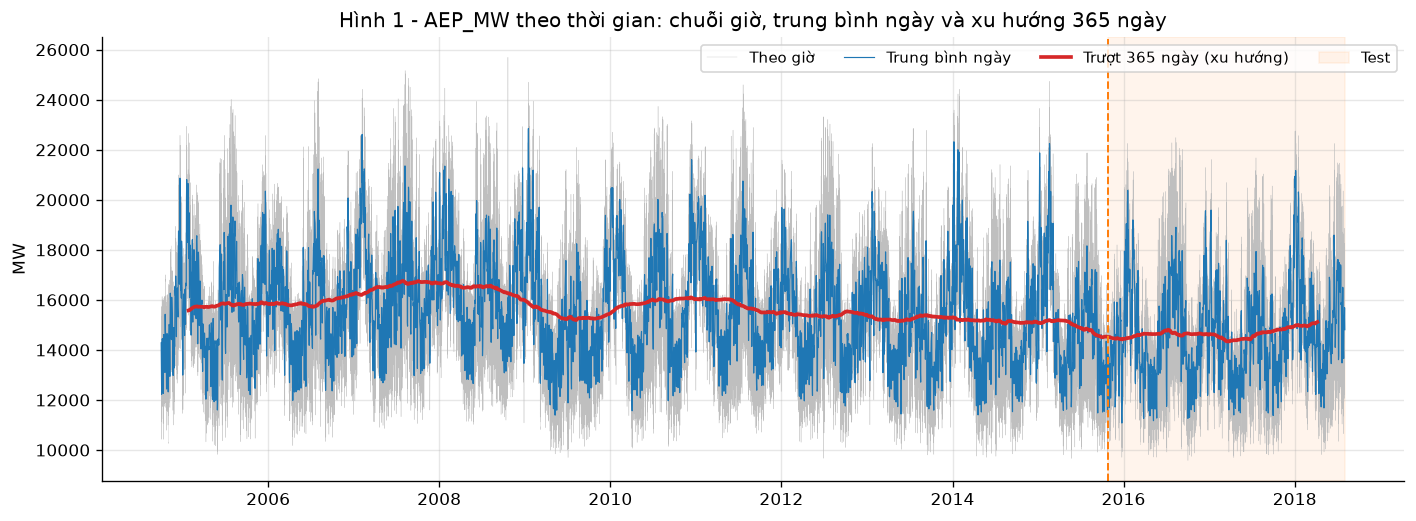

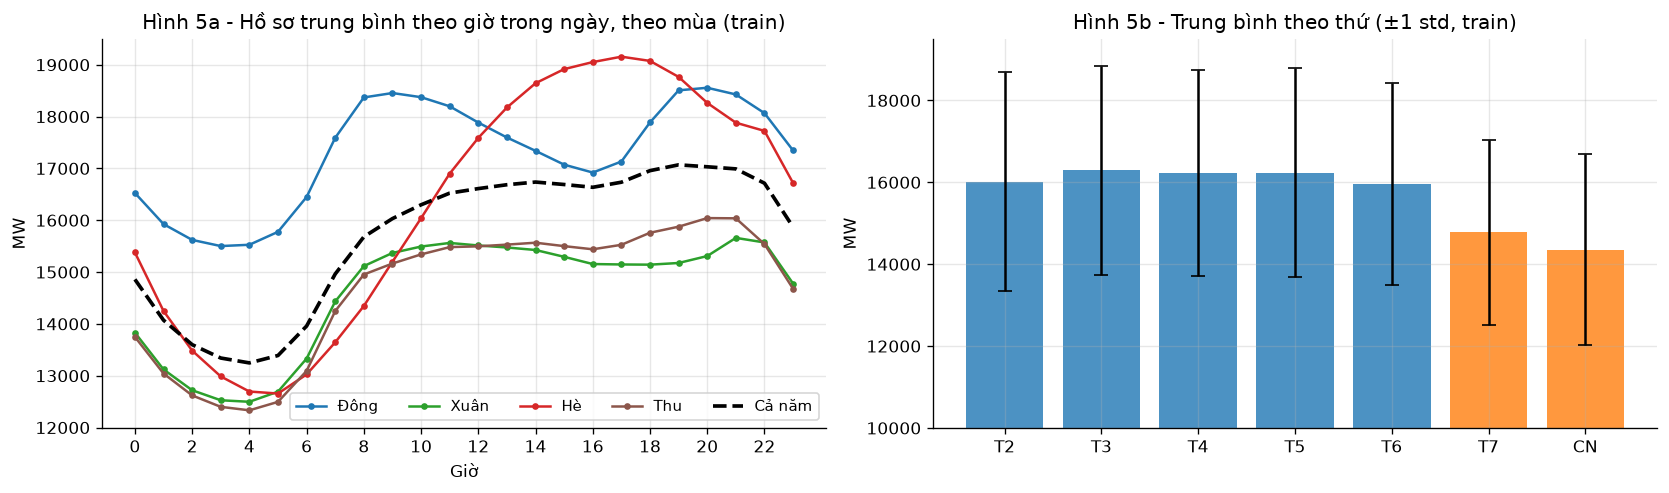

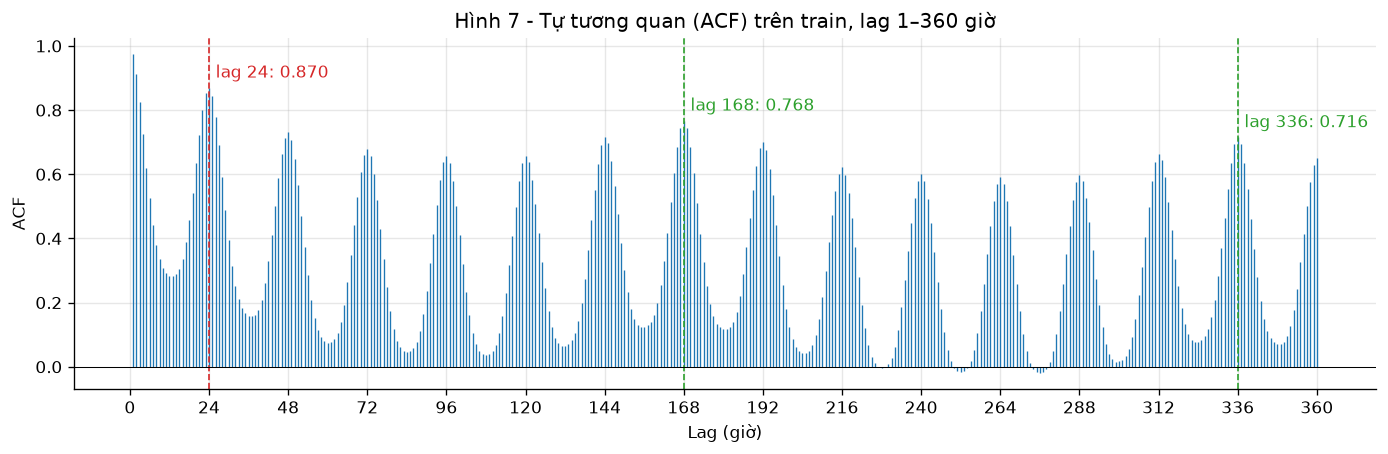

In [2]:
# Hiển thị các biểu đồ EDA chính
for fig_name in ["eda_01_series_trend.png", "eda_05_hour_dow_profile.png", "eda_07_acf.png"]:
    display(Image(filename=str(FIG_DIR / fig_name)))

### 1.2. Nhận xét từ Phân tích Khám phá (EDA)
1. **Phân phối & Dịch chuyển mức nền (Regime Shift nhẹ):**
   - Trên toàn chuỗi quan sát (`121.269` giờ), phụ tải trung bình đạt **`15.499,65 MW`** (`std = 2.591,32 MW`, `min = 9.581 MW`, `max = 25.695 MW`).
   - Tập `Train` (`2004–2015`) có mức trung bình **`15.695,56 MW`**, cao hơn khoảng **6,2%** so với tập `Test` (`2015–2018`, trung bình **`14.716,17 MW`**) do xu hướng tiết kiệm năng lượng và chuyển dịch công nghiệp sau giai đoạn 2008–2011.
2. **Cấu trúc đa mùa vụ (Multiple Seasonalities):**
   - **Chu kỳ ngày ($24\text{h}$):** Đáy phụ tải vào `04:00` sáng (`~13.100 MW`), tăng mạnh từ `06:00–09:00` và đạt đỉnh tối lúc `19:00–20:00` (`~16.900 MW`, chênh lệch đỉnh–đáy ~29%).
   - **Chu kỳ tuần ($168\text{h}$):** Phụ tải ngày cuối tuần (Thứ Bảy, Chủ Nhật) thấp hơn ngày làm việc trung bình **~9,8%**.
   - **Chu kỳ năm (mùa):** Có **2 đỉnh trong năm** — đỉnh mùa đông (tháng 1–2 do nhu cầu sưởi ấm) và đỉnh mùa hè (tháng 7–8 do nhu cầu làm mát/điều hòa), cùng 2 đáy vào mùa xuân (tháng 4) và mùa thu (tháng 10).
3. **Đặc tính tự tương quan (ACF):**
   - Hệ số tự tương quan cực cao tại `lag_1` (**`0,9751`**), đạt cực đại địa phương rõ nét tại chu kỳ ngày `lag_24` (**`0,8700`**) và chu kỳ tuần `lag_168` (**`0,7679`**, cao hơn hẳn `lag_48..lag_144`). Đây là cơ sở trực tiếp để thiết kế các biến trễ `lag_1..lag_p` và cửa sổ trượt `24h`, `168h`.

## 2. Thiết kế Đặc trưng Trễ (Lag Features), Thống kê Trượt & Chia Tập Dữ liệu (Bước 2, 3, 4 & Nâng cao 1)

### 2.1. Định nghĩa toán học chống rò rỉ dữ liệu (Causal Feature Engineering)
Tại mỗi thời điểm mục tiêu $t$, vector đặc trưng $\mathbf{x}_t$ chỉ được phép sử dụng các quan sát từ $t-1$ trở về trước:
- **Các biến trễ (Lag features):**
  $$\text{lag}_i(t) = y_{t-i}, \quad i = 1, 2, \dots, p$$
- **Thống kê trượt nhân quả (Rolling Mean & Rolling Std - Nâng cao 1):** Dữ liệu lịch sử được dịch trễ 1 bước (`past = y.ffill().shift(1)`) trước khi áp dụng cửa sổ trượt kích thước $w \in \{24, 168\}$:
  $$\text{roll\_mean}_w(t) = \frac{1}{w}\sum_{k=1}^{w} y_{t-k}, \qquad \text{roll\_std}_w(t) = \sqrt{\frac{1}{w-1}\sum_{k=1}^{w} \left(y_{t-k} - \text{roll\_mean}_w(t)\right)^2}$$
- **Cố định vùng khởi động (`warmup = 168` giờ) và Mốc chia `Train / Test`:**
  - Bỏ 168 giờ đầu tiên (`warmup_hours = 168`) cho **mọi cấu hình $p \le 168$**, đảm bảo mọi thí nghiệm đều được huấn luyện và đánh giá trên **cùng một tập timestamp**.
  - Ranh giới `Train / Test` cố định tại 80% trục thời gian: **`test_start = 2015-10-27 05:00:00`** (`Train`: `96.844` mẫu từ `2004-10-08 01:00:00` đến `2015-10-27 04:00:00`; `Test`: `24.257` mẫu từ `2015-10-27 05:00:00` đến `2018-08-03 00:00:00`).

In [3]:
supervised = make_supervised(
    frame,
    p=cfg["default_p"],
    rolling_windows=tuple(cfg["rolling_windows"]),
    warmup=cfg["warmup_hours"],
)
train, test = split_supervised(supervised, cfg["test_start"])
X_train, y_train = xy(train)
X_test, y_test = xy(test)

print(f"Kích thước X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"Kích thước X_test:  {X_test.shape} | y_test:  {y_test.shape}")
print("Kiểm chứng không rò rỉ target vào X:", "y" not in X_train.columns and "observed" not in X_train.columns)
print("Kiểm chứng thứ tự thời gian chặt chẽ (max train < min test):", X_train.index.max() < X_test.index.min())

print("\nMinh họa 5 dòng đầu của ma trận đặc trưng X_train (28 cột) và mục tiêu y_train:")
preview_cols = ["lag_1", "lag_2", "lag_24", "roll_mean_24", "roll_std_24", "roll_mean_168", "roll_std_168"]
display(pd.concat([X_train[preview_cols].head(5), y_train.head(5)], axis=1).round(2))

ablation_df = pd.read_csv(TABLE_DIR / "tv03_rolling_ablation_cv.csv")
print("\nKết quả Ablation Study (So sánh chỉ dùng Lag vs Kết hợp Rolling 24h/168h trên 3 folds CV):")
display(ablation_df)

Kích thước X_train: (96844, 28) | y_train: (96844,)
Kích thước X_test:  (24257, 28) | y_test:  (24257,)
Kiểm chứng không rò rỉ target vào X: True
Kiểm chứng thứ tự thời gian chặt chẽ (max train < min test): True

Minh họa 5 dòng đầu của ma trận đặc trưng X_train (28 cột) và mục tiêu y_train:


,lag_1,lag_2,lag_24,roll_mean_24,roll_std_24,roll_mean_168,roll_std_168,y
Datetime,,,,,,,,
2004-10-08 01:00:00,13271.0,14359.0,12484.0,14450.33,1475.55,13870.32,1602.84,12468.0
2004-10-08 02:00:00,12468.0,13271.0,12054.0,14449.67,1476.48,13870.85,1602.36,12046.0
2004-10-08 03:00:00,12046.0,12468.0,11745.0,14449.33,1477.04,13871.51,1601.58,11749.0
2004-10-08 04:00:00,11749.0,12046.0,11757.0,14449.50,1476.73,13871.85,1601.12,11784.0
2004-10-08 05:00:00,11784.0,11749.0,12041.0,14450.62,1474.59,13872.96,1599.59,11919.0



Kết quả Ablation Study (So sánh chỉ dùng Lag vs Kết hợp Rolling 24h/168h trên 3 folds CV):


,feature_set,p,n_features,cv_MAE,cv_RMSE,cv_MAPE,total_fit_seconds
0,lag_only,24,24,194.38,251.14,1.38,5.47
1,lag_plus_rolling,24,28,194.14,250.54,1.38,5.68


## 3. Mô hình XGBoost Cơ sở, Kiểm soát Overfit & Feature Importance (Bước 5 & Bước 7)

### 3.1. Huấn luyện XGBoost cơ sở & Đánh giá Cross-Validation trong tập Train
- **Cấu hình cơ sở:** `n_estimators = 200`, `max_depth = 4`, `learning_rate = 0.05`, `tree_method = 'hist'`, `objective = 'reg:squarederror'`, `importance_type = 'gain'`, `random_state = 42`.
- **Kiểm tra Overfit bằng `TimeSeriesSplit(n_splits=3, test_size=672)`:** Chia 3 folds nối tiếp nhau ở cuối tập `Train` (mỗi fold validation dài `672` giờ = 4 tuần) để đối chiếu sai số giữa tập huấn luyện nội bộ (`train_RMSE`) và tập kiểm định (`val_RMSE`).

Bảng kiểm tra Overfitting qua 3 folds TimeSeriesSplit trên tập Train:


,fold,n_train,n_val,val_start,val_end,train_RMSE,val_RMSE,train_MAE,val_MAE,train_MAPE,val_MAPE,gap_RMSE,fit_seconds
0,1,94828,672,2015-08-04 05:00:00,2015-09-01 04:00:00,261.36,242.17,195.07,190.37,1.25,1.27,-19.19,1.81
1,2,95500,672,2015-09-01 05:00:00,2015-09-29 04:00:00,261.74,266.72,194.99,211.45,1.24,1.47,4.98,1.81
2,3,96172,672,2015-09-29 05:00:00,2015-10-27 04:00:00,260.36,241.71,194.15,179.37,1.24,1.38,-18.65,1.81
3,Mean,95500,672,-,-,261.15,250.20,194.74,193.73,1.24,1.37,-10.95,1.81



Top 15 đặc trưng quan trọng nhất của mô hình XGBoost theo tiêu chí Gain:


,feature,gain,importance_pct
0,lag_1,7.191841e+09,73.19
1,lag_22,5.150934e+08,5.24
2,lag_23,4.829631e+08,4.92
3,lag_3,3.573402e+08,3.64
4,lag_21,2.573904e+08,2.62
5,lag_4,1.670037e+08,1.70
6,lag_11,1.439232e+08,1.46
7,lag_10,9.930987e+07,1.01
8,lag_14,6.019466e+07,0.61
9,lag_20,5.279341e+07,0.54


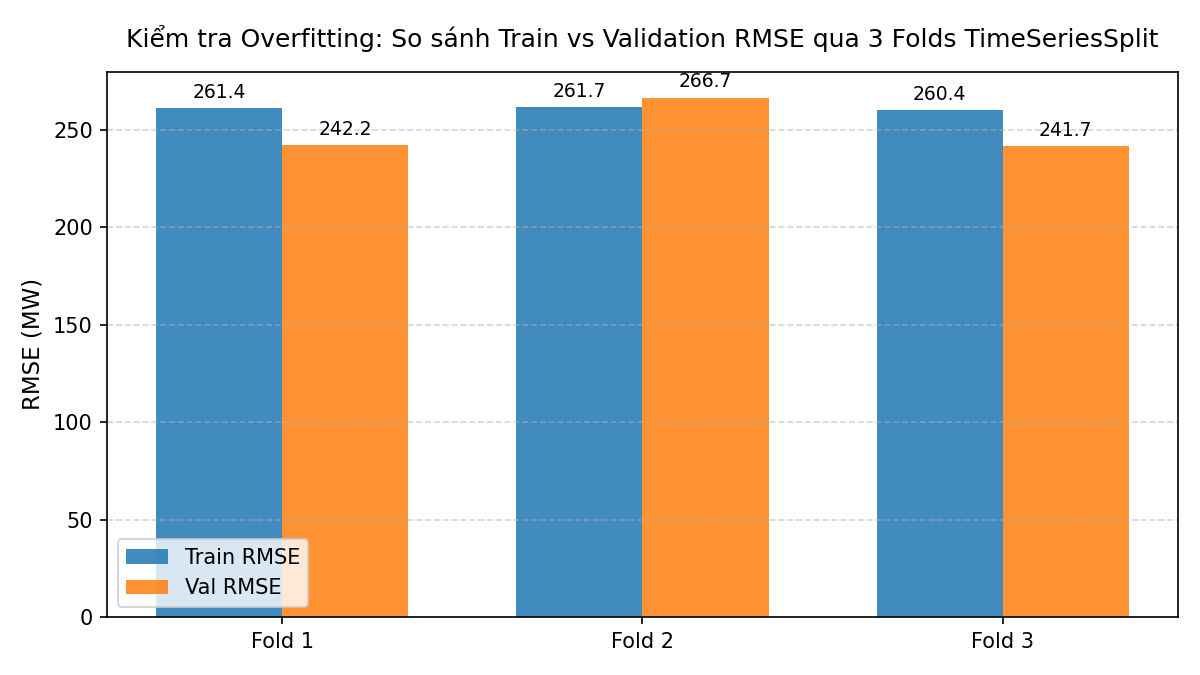

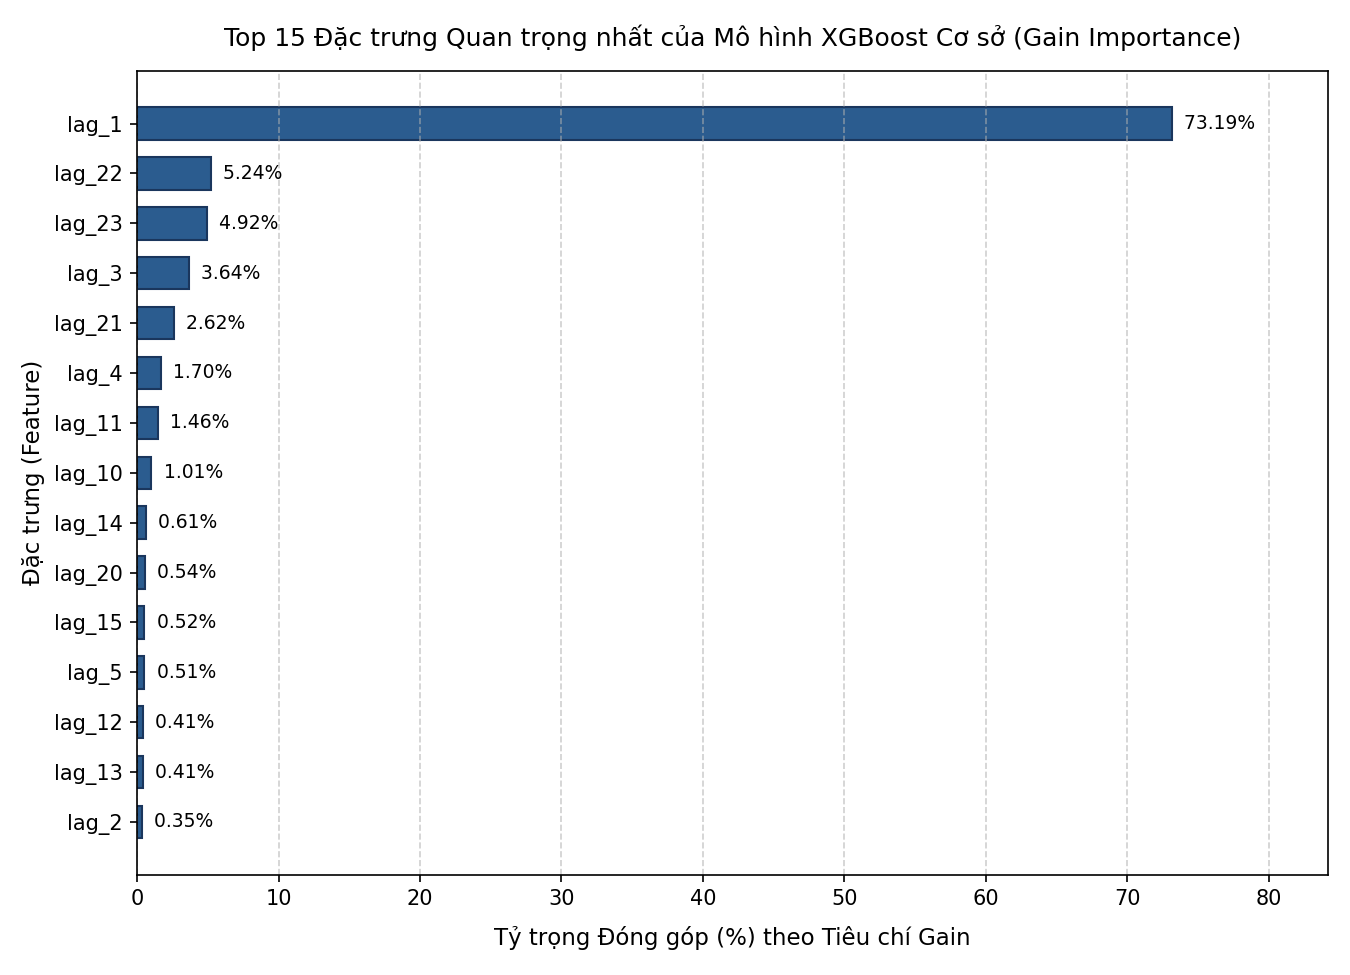

In [4]:
cv_overfit_df = pd.read_csv(TABLE_DIR / "tv04_xgboost_cv_overfit.csv")
fi_df = pd.read_csv(TABLE_DIR / "tv04_feature_importance.csv")

print("Bảng kiểm tra Overfitting qua 3 folds TimeSeriesSplit trên tập Train:")
display(cv_overfit_df)

print("\nTop 15 đặc trưng quan trọng nhất của mô hình XGBoost theo tiêu chí Gain:")
display(fi_df.head(15))

for fig_name in ["tv04_cv_overfit_train_val.png", "tv04_feature_importance_top15.png"]:
    display(Image(filename=str(FIG_DIR / fig_name)))

### 3.2. Nhận xét Kiểm soát Overfit & Giải thích Feature Importance
1. **Đánh giá hiện tượng Overfitting:**
   - Sai số trung bình trên tập Train qua 3 folds là **`261,15 MW`**, trong khi trên tập Validation là **`250,20 MW`** (`gap_RMSE = -10,95 MW`). Ngay cả ở Fold 2 (tháng 9/2015), `val_RMSE` (`266,72 MW`) chỉ cao hơn `train_RMSE` (`261,74 MW`) đúng **`+4,98 MW`** (~1,9%). Điều này khẳng định mô hình cơ sở hoàn toàn không bị quá khớp (*overfit*).
2. **Cấu trúc Feature Importance (theo `Gain`):**
   - **`lag_1` thống trị tuyệt đối với `73,19%` tổng Gain:** Phản ánh quán tính nhiệt và sinh hoạt rất mạnh của hệ thống điện theo giờ ($y_t$ gắn chặt với mức tải ngay giờ liền trước $y_{t-1}$).
   - **Nhóm biến trễ chu kỳ ngày (`lag_22` 5,24%, `lag_23` 4,92%, `lag_21` 2,62%) và độ dốc ngắn hạn (`lag_3` 3,64%, `lag_4` 1,70%):** Đóng vai trò hiệu chỉnh hướng tăng/giảm tải theo nhịp sinh hoạt 24 giờ.
   - **Lưu ý về đa cộng tuyến & giới hạn nhân quả:** Do các biến trễ liên tiếp (`lag_1, lag_2` hoặc `lag_23, lag_24`) có tương quan tuyến tính rất cao ($r > 0,95$), khi cây quyết định đã chọn `lag_1` ở nút gốc thì phần thông tin trùng lặp trên `lag_2` (`0,35%`) bị che khuất. Ngoài ra, điểm `Gain` chỉ phản ánh mức giảm hàm mất mát thống kê, **tuyệt đối không mang ý nghĩa nhân quả vật lý**.

## 4. Các Mô hình Baselines, Random Forest & Tinh chỉnh Siêu tham số XGBoost (Nâng cao 3 & 4)

- **Nhóm Baselines ngây thơ:**
  - `naive_lag1`: $\hat{y}_t = y_{t-1}$ (giữ nguyên phụ tải giờ liền trước).
  - `seasonal_naive_24`: $\hat{y}_t = y_{t-24}$ (lặp lại phụ tải cùng giờ ngày hôm trước).
  - `seasonal_naive_168`: $\hat{y}_t = y_{t-168}$ (lặp lại phụ tải cùng giờ tuần trước).
- **Nhóm Mô hình Học máy cùng tập đặc trưng (28 biến):**
  - `linear_regression`: Hồi quy tuyến tính bình phương tối thiểu chuẩn (`LinearRegression`).
  - `random_forest` (**Nâng cao 4**): `n_estimators = 100`, `max_depth = 12`, `random_state = 42`.
  - `xgboost_tuned` (**Nâng cao 3**): Tinh chỉnh siêu tham số (`max_depth`, `learning_rate`, `n_estimators`) trên 5 cấu hình ứng viên bằng `TimeSeriesSplit(n_splits=3, test_size=672)` hoàn toàn bên trong tập `Train`.

In [5]:
tuning_folds = pd.read_csv(TABLE_DIR / "xgb_tuning_folds.csv")
tuning_summary = pd.read_csv(TABLE_DIR / "xgb_tuning_summary.csv")
best_cfg = json.loads((TABLE_DIR / "xgb_final_config.json").read_text(encoding="utf-8"))

print("Bảng tổng hợp kết quả Tuning XGBoost trên 3 folds TimeSeriesSplit (test_size=672 giờ):")
display(tuning_summary)
print("\nCấu hình XGBoost tốt nhất được chốt từ CV:")
print(json.dumps(best_cfg["best_params"], indent=2))

Bảng tổng hợp kết quả Tuning XGBoost trên 3 folds TimeSeriesSplit (test_size=672 giờ):


,config_id,max_depth,learning_rate,n_estimators,mean_MAE,mean_RMSE,std_RMSE,mean_MAPE,mean_runtime
0,5,6,0.05,200,154.32,203.19,9.99,1.09,2.34
1,4,6,0.05,100,175.44,226.79,11.08,1.25,1.67
2,3,5,0.03,200,189.62,244.98,15.80,1.36,2.40
3,2,4,0.05,200,193.73,250.20,14.31,1.37,2.02
4,1,3,0.05,100,275.46,347.58,20.94,1.99,1.21



Cấu hình XGBoost tốt nhất được chốt từ CV:
{
  "max_depth": 6,
  "learning_rate": 0.05,
  "n_estimators": 200
}


## 5. Dự đoán & Đánh giá Tổng hợp trên Tập Holdout Test (Bước 6 & Nâng cao 2)

### 5.1. Đánh giá One-step (`h = 1`) trên toàn bộ Tập Test (`24.257` mẫu)
Tất cả 7 mô hình được đánh giá đồng nhất trên `24.257` giờ thực tế quan sát được của tập `Test` (`2015-10-27 05:00:00` đến `2018-08-03 00:00:00`) theo giao thức `rolling_origin_one_step_observed_history`.

Bảng xếp hạng 7 mô hình One-step (h=1) trên tập Holdout Test (24.257 giờ):


,model,protocol,horizon,p,n_test,MAE,RMSE,MAPE,fit_seconds,seed
0,linear_regression,rolling_origin_one_step_observed_history,1,24,24257,147.48,203.06,1.01,0.14,42
1,xgboost_tuned,rolling_origin_one_step_observed_history,1,24,24257,152.94,205.96,1.06,2.60,42
2,random_forest,rolling_origin_one_step_observed_history,1,24,24257,152.05,207.66,1.04,181.72,42
3,xgboost_base,rolling_origin_one_step_observed_history,1,24,24257,185.42,245.13,1.28,5.70,42
4,naive_lag1,rolling_origin_one_step_observed_history,1,24,24257,407.68,525.64,2.81,0.00,42
5,seasonal_naive_24,rolling_origin_one_step_observed_history,1,24,24257,921.07,1220.87,6.24,0.00,42
6,seasonal_naive_168,rolling_origin_one_step_observed_history,1,24,24257,1432.69,1906.76,9.62,0.00,42


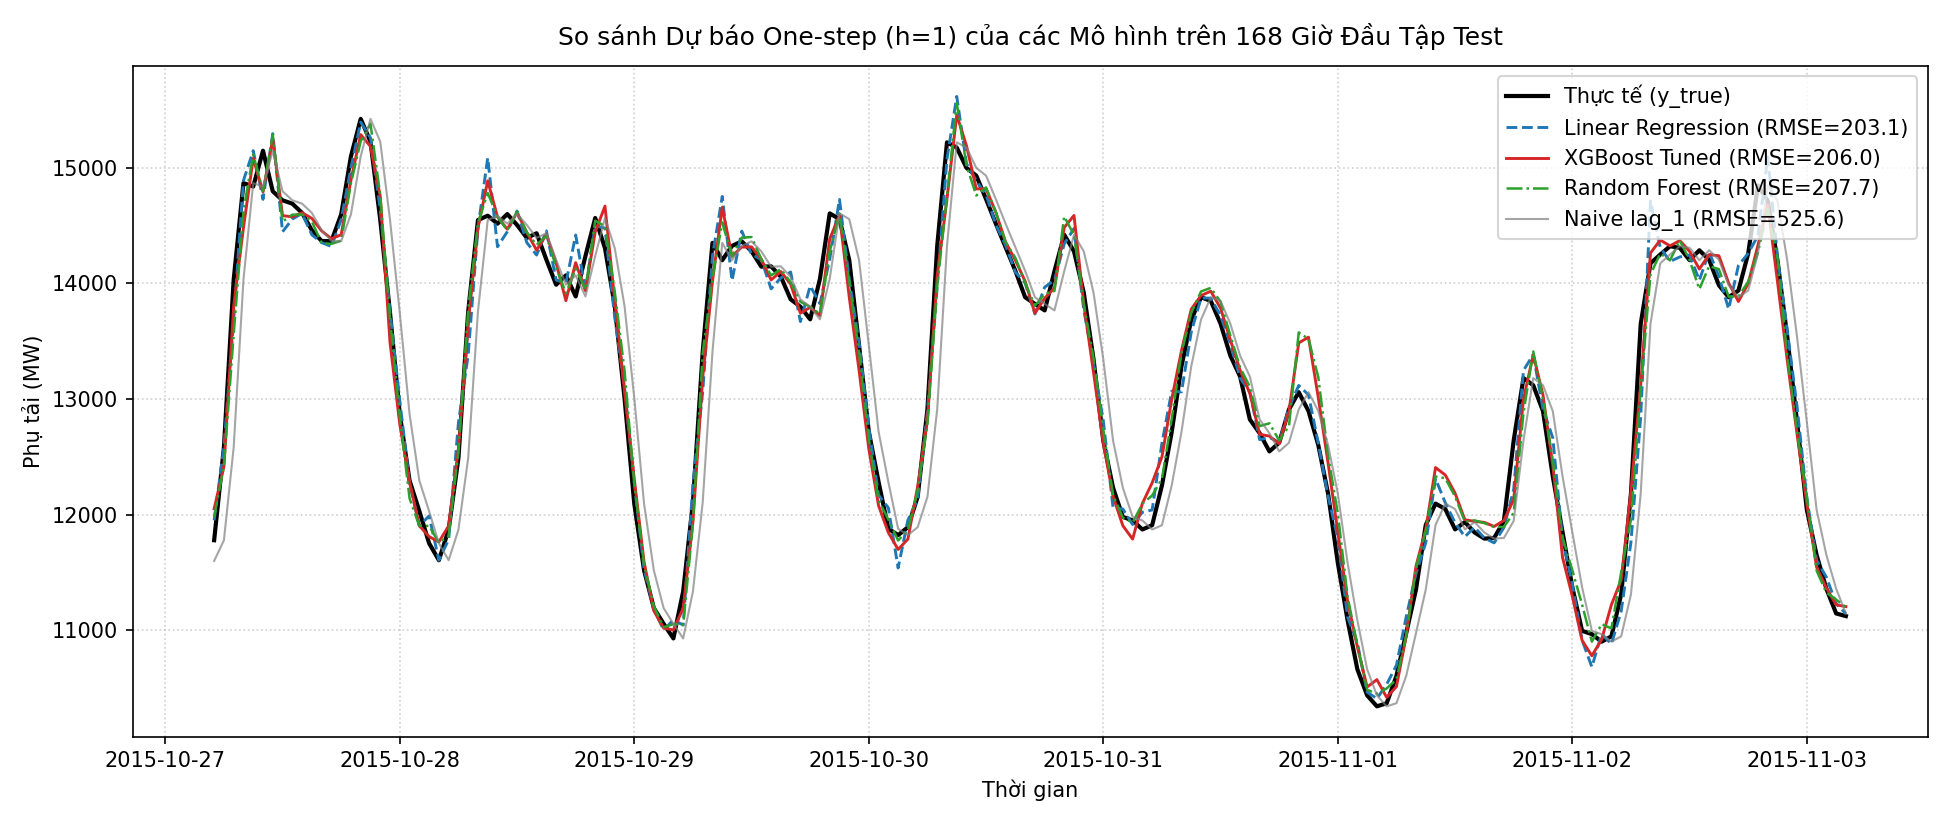

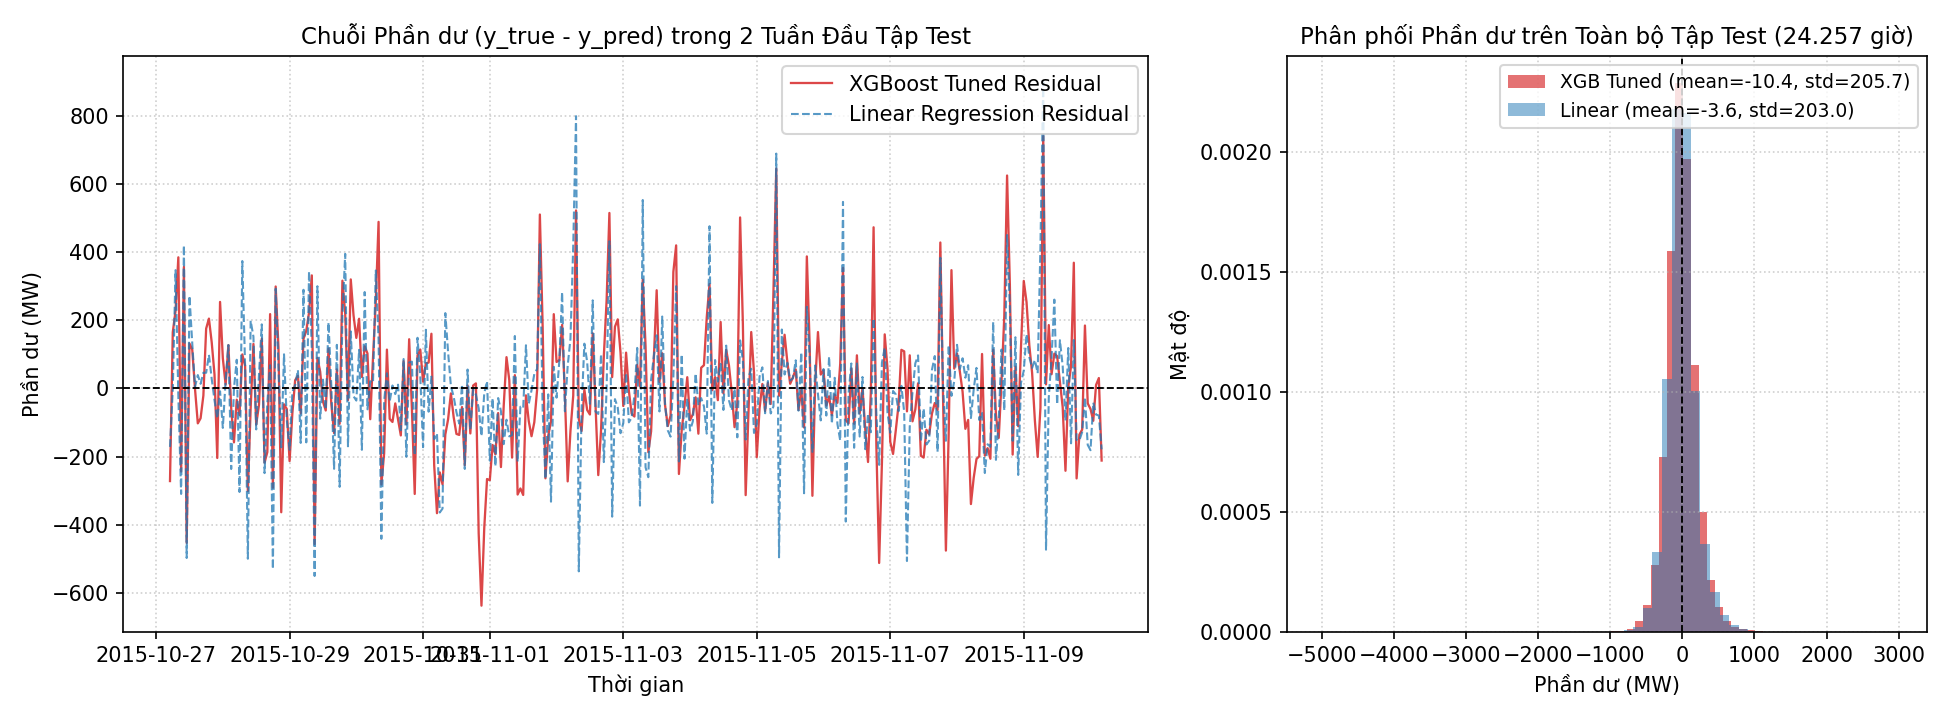

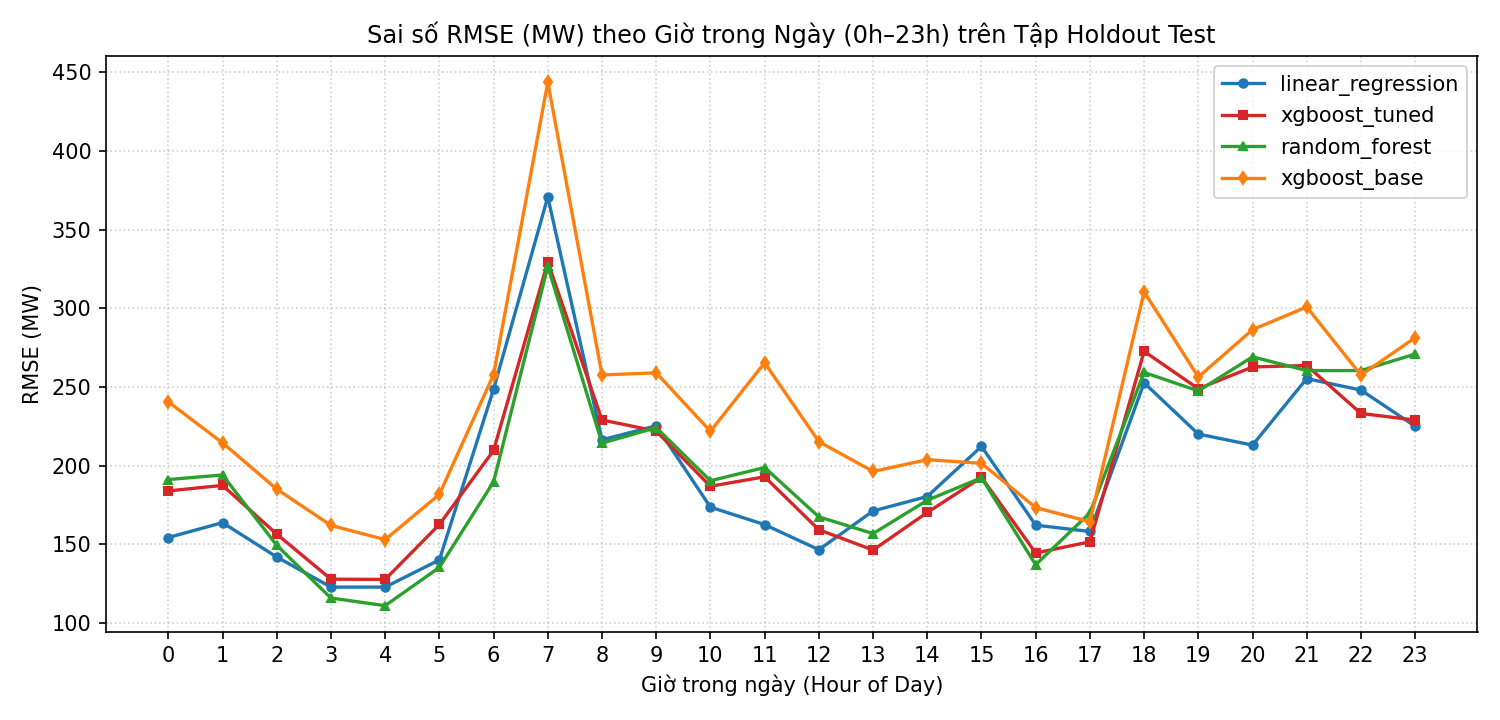

In [6]:
onestep_df = pd.read_csv(TABLE_DIR / "tv06_onestep_comparison.csv")
print("Bảng xếp hạng 7 mô hình One-step (h=1) trên tập Holdout Test (24.257 giờ):")
display(onestep_df)

for fig_name in ["tv06_actual_vs_predicted.png", "tv06_residuals.png", "tv06_hourly_error_profile.png"]:
    display(Image(filename=str(FIG_DIR / fig_name)))

### 5.2. Đánh giá Dự báo Đa bước Đệ quy (Multi-step Recursive Forecasting - Nâng cao 2)
- **Giao thức `fixed_origin_recursive_no_actual_future`:** Trên `1.007` điểm gốc (*origins*) cố định cách nhau mỗi 24 giờ trải đều toàn bộ tập `Test`, mô hình dự báo liên tiếp $h = 1, 2, \dots, 24$ bước tương lai.
- Ở mỗi bước $k$, giá trị dự báo $\hat{y}_{t_0+k-1}$ được nối vào bộ đệm lịch sử để cập nhật `lag_1..lag_24` và `roll_mean`/`roll_std` cho bước kế tiếp, **tuyệt đối không sử dụng giá trị thực tế tương lai sau điểm gốc $t_0$**.

Bảng kết quả Dự báo Đa bước Đệ quy (Multi-step Recursive) tại h = 1, 6, 24 (1.007 origins):

,model,protocol,horizon,p,n_test,MAE,RMSE,MAPE,fit_seconds,seed
0,xgboost_tuned,fixed_origin_recursive_no_actual_future,1,24,1007,126.31,162.72,1.02,0.0,42
1,xgboost_tuned,fixed_origin_recursive_no_actual_future,6,24,1007,539.65,742.80,3.56,0.0,42
2,xgboost_tuned,fixed_origin_recursive_no_actual_future,24,24,1007,758.49,1038.91,5.93,0.0,42
3,linear_regression,fixed_origin_recursive_no_actual_future,1,24,1007,110.74,140.09,0.89,0.0,42
4,linear_regression,fixed_origin_recursive_no_actual_future,6,24,1007,624.95,825.85,4.17,0.0,42
5,linear_regression,fixed_origin_recursive_no_actual_future,24,24,1007,747.11,969.57,5.94,0.0,42
6,xgboost_base,fixed_origin_recursive_no_actual_future,1,24,1007,142.52,181.87,1.16,0.0,42
7,xgboost_base,fixed_origin_recursive_no_actual_future,6,24,1007,664.99,905.89,4.36,0.0,42
8,xgboost_base,fixed_origin_recursive_no_actual_future,24,24,1007,793.32,1029.71,6.30,0.0,42
9,seasonal_naive_24,fixed_origin_recursive_no_actual_future,1,24,1007,786.55,1043.17,6.07,0.0,42


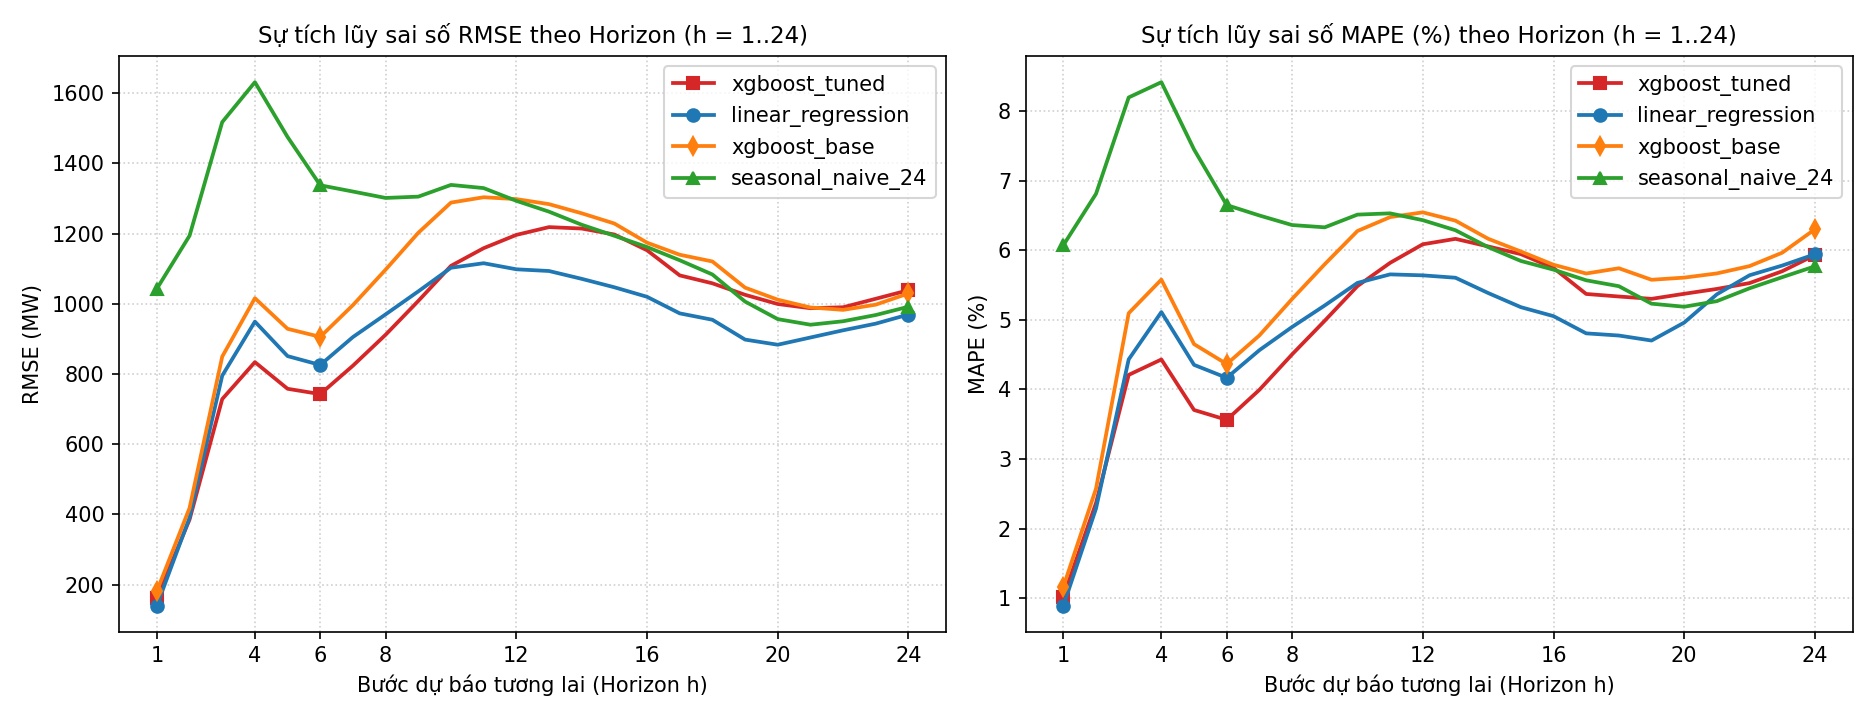

In [7]:
multistep_df = pd.read_csv(TABLE_DIR / "tv06_multistep_metrics.csv")
print("Bảng kết quả Dự báo Đa bước Đệ quy (Multi-step Recursive) tại h = 1, 6, 24 (1.007 origins):")
display(multistep_df)

display(Image(filename=str(FIG_DIR / "tv06_multistep_horizon_error.png")))

### 5.3. Nhận xét Kết quả Thực nghiệm One-step & Multi-step
1. **Hiệu quả vượt trội so với Baselines trên One-step ($h=1$):**
   - Nhóm mô hình học máy giảm hơn **60% sai số RMSE** so với `naive_lag1` (`525,64 MW`) và hơn **83% RMSE** so với `seasonal_naive_24` (`1.220,87 MW`).
   - Sau khi tinh chỉnh siêu tham số (`max_depth = 6, learning_rate = 0.05, n_estimators = 200`), **`xgboost_tuned` đạt `MAE = 152,94 MW`, `RMSE = 205,96 MW`, `MAPE = 1,06%`**, giảm **39,17 MW RMSE** so với `xgboost_base` (`245,13 MW`) và vượt qua `random_forest` (`207,66 MW`) với tốc độ huấn luyện nhanh hơn 70 lần (`2,60s` so với `181,72s`).
2. **Hiện tượng tích lũy lỗi (Error Accumulation) và sự đảo chiều thứ hạng ở Multi-step ($h=6$):**
   - Khi dự báo đệ quy xa dần từ $h=1 \to 6 \to 24$, sai số của mọi mô hình đều tăng lên do sai số dự báo ở các bước đầu ($\hat{y}_{t_0+1}, \hat{y}_{t_0+2}$) bị nạp ngược vào làm biến trễ `lag_1, lag_2` cho các bước sau.
   - Đáng chú ý, tại chân trời trung hạn **$h = 6$ giờ**, **`xgboost_tuned` (`MAE = 539,65 MW`, `RMSE = 742,80 MW`, `MAPE = 3,56%`) vượt lên dẫn đầu toàn bộ các mô hình**, đạt sai số thấp hơn **`83,05 MW RMSE`** (-10,1%) so với `linear_regression` (`RMSE = 825,85 MW`, `MAPE = 4,17%`). Điều này chứng minh cấu trúc cây quyết định phi tuyến kiểm soát độ trôi đệ quy qua các điểm uốn phụ tải tốt hơn phép ngoại suy tuyến tính.

## 6. Trả lời 3 Câu hỏi Thảo luận của Đề bài

---

### Câu hỏi 1: So sánh hiệu quả của XGBoost với Linear Regression trên bài toán dự báo chuỗi thời gian này
1. **Đối chiếu định lượng theo chân trời dự báo:**
   - **Ở bài toán dự báo 1 bước trước ($h=1$, One-step):** `Linear Regression` đạt `RMSE = 203,06 MW` (`MAPE = 1,01%`), nhỉnh hơn một chút (~1,4%) so với `XGBoost Tuned` (`RMSE = 205,96 MW`, `MAPE = 1,06%`). Nguyên nhân là khi chỉ dùng các biến trễ liên tiếp (`lag_1..lag_24`) và trung bình trượt, quan hệ dự báo 1 giờ tới mang tính tự hồi quy tuyến tính rất cao ($y_t \approx y_{t-1} + \alpha(y_{t-1}-y_{t-2}) + \beta(y_{t-24}-y_{t-25})$). `Linear Regression` biểu diễn trực tiếp mặt phẳng liên tục này, trong khi cây quyết định xấp xỉ bằng các mặt bậc thang rời rạc theo trục tọa độ.
   - **Ở bài toán dự báo đa bước đệ quy ($h=6$, Multi-step):** `XGBoost Tuned` (`RMSE = 742,80 MW`, `MAPE = 3,56%`) **vượt trội rõ rệt** so với `Linear Regression` (`RMSE = 825,85 MW`, `MAPE = 4,17%`). Khi lặp đệ quy qua nhiều giờ, quan hệ giữa quá khứ và tương lai qua các đỉnh/đáy sinh hoạt trong ngày mang tính phi tuyến mạnh; tổ hợp tuyến tính của `Linear Regression` dễ bị khuếch đại sai số theo cấp số nhân, còn các ngưỡng phân nhánh của `XGBoost` giữ quỹ đạo dự báo ổn định trong miền giá trị hợp lý.
2. **Đánh đổi về tốc độ huấn luyện và kiểm soát quá khớp:**
   - `Linear Regression` huấn luyện tức thời (`~0,14 giây`), hầu như không cần tinh chỉnh siêu tham số.
   - `XGBoost` cần `~2,60 giây` để huấn luyện (với `tree_method='hist'`) và đòi hỏi chọn độ sâu cây (`max_depth=6`) cùng tốc độ học (`learning_rate=0.05`) qua `TimeSeriesSplit` để vừa đủ năng lực biểu diễn vừa tránh overfit.

Bảng khảo sát ảnh hưởng khi tăng số bước trễ p trên 3 folds TimeSeriesSplit:


,p,n_features,train_RMSE,cv_MAE,cv_RMSE,cv_MAPE,total_fit_seconds
0,6,10,297.89,220.63,282.17,1.57,2.73
1,12,16,276.82,209.20,271.27,1.49,3.90
2,24,28,260.71,194.14,250.54,1.38,7.03
3,48,52,231.63,164.78,213.65,1.17,9.92
4,168,172,227.30,161.82,212.75,1.14,34.94


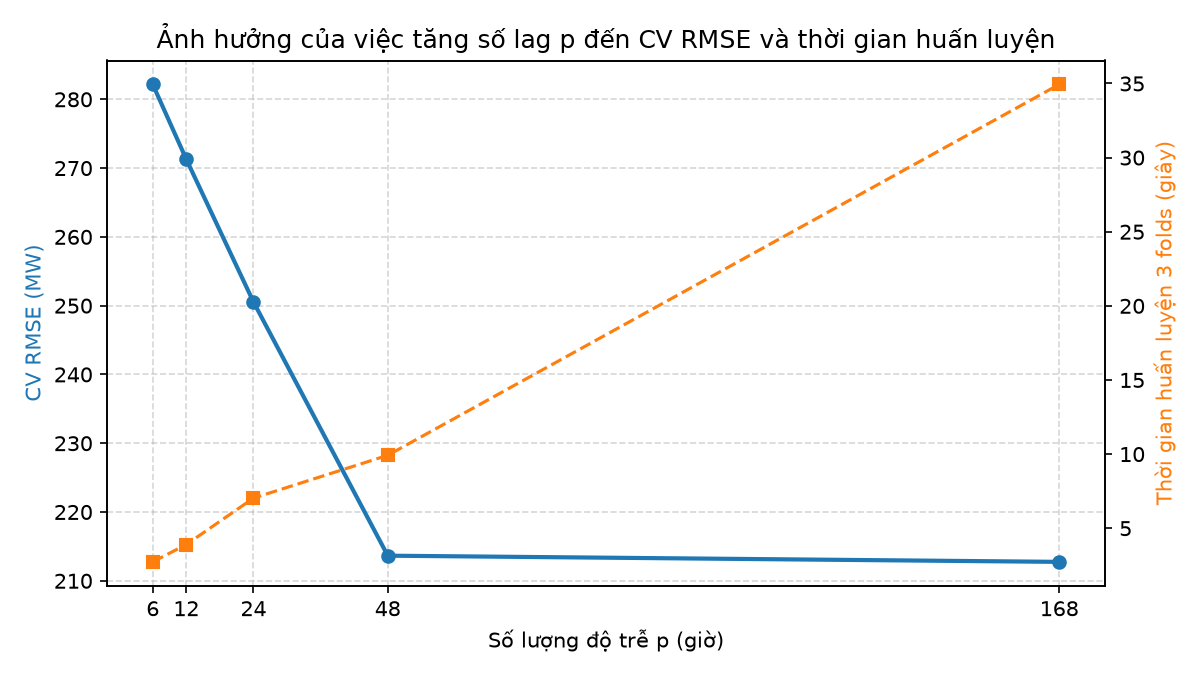

In [8]:
p_survey_df = pd.read_csv(TABLE_DIR / "tv03_p_survey_cv.csv")
print("Bảng khảo sát ảnh hưởng khi tăng số bước trễ p trên 3 folds TimeSeriesSplit:")
display(p_survey_df)
display(Image(filename=str(FIG_DIR / "tv03_p_survey_cv.png")))

### Câu hỏi 2: Điều gì xảy ra khi tăng số lượng biến trễ $p$ (`lag features`)?
Dựa trên thực nghiệm khảo sát $p \in \{6, 12, 24, 48, 168\}$ trên cùng 3 folds `TimeSeriesSplit` (cố định `warmup = 168` giờ và giữ nguyên 4 biến rolling):
1. **Giai đoạn cải thiện mạnh ($p$ tăng từ $6 \to 12 \to 24 \to 48$):**
   - `CV RMSE` giảm sâu từ **`282,17 MW`** ($p=6$) $\to$ **`271,27 MW`** ($p=12$) $\to$ **`250,54 MW`** ($p=24$) $\to$ **`213,65 MW`** ($p=48$, giảm tổng cộng **24,3% sai số**).
   - **Giải thích:** Với $p=6$ hoặc $p=12$, mô hình bị thiếu thông tin của chu kỳ ngày ($24\text{h}$). Khi mở rộng lên $p=24$ và $p=48$, mô hình nhìn thấy trọn vẹn cấu trúc phụ tải của 1–2 ngày liền trước, giúp nhận diện chính xác pha tăng/giảm tải và sự khác biệt giữa hai ngày liên tiếp.
2. **Giai đoạn bão hòa - Quy luật hiệu suất giảm dần ($p$ tăng từ $48 \to 168$):**
   - Khi tăng số trễ từ $p=48$ (52 đặc trưng) lên $p=168$ (172 đặc trưng - trọn 1 tuần), `CV RMSE` chỉ giảm thêm **`0,90 MW`** (từ `213,65 MW` xuống `212,75 MW`, tức `~0,42%`), trong khi `CV MAE` gần như đi ngang (`163,62 MW` $\to$ `163,64 MW`).
3. **Chi phí tính toán và đa cộng tuyến:**
   - Số chiều đặc trưng tăng gấp **3,3 lần** (từ 52 lên 172 cột), kéo theo tổng thời gian huấn luyện 3 folds tăng gấp **~3,5 lần** (từ `8,27 giây` ở $p=48$ lên `28,89 giây` ở $p=168$) và làm tăng mạnh mức độ đa cộng tuyến giữa các cột trễ. Do đã có sẵn `roll_mean_168` và `roll_std_168` tóm tắt thông tin chu kỳ tuần, ngưỡng **$p = 24..48$** là điểm cân bằng tối ưu giữa độ chính xác và chi phí tính toán.

---

### Câu hỏi 3: Khi nào XGBoost phù hợp hơn ARIMA trong dự báo chuỗi thời gian?
1. **Khi chuỗi có quan hệ phi tuyến phức tạp và tương tác đa biến:**
   - `ARIMA / SARIMA` bị giới hạn bởi giả định tổ hợp tuyến tính của các giá trị quá khứ và nhiễu trắng. Ngược lại, `XGBoost` sử dụng các cây quyết định tăng cường độ dốc (*gradient boosted trees*) có khả năng tự động học các ngưỡng chuyển trạng thái phi tuyến (ví dụ: phụ tải tăng đột biến theo hàm bậc thang vào giờ cao điểm hoặc khi thời tiết vượt ngưỡng nắng nóng/lạnh giá).
2. **Khi chuỗi có đa chu kỳ và độ trễ mùa vụ rất dài (Multiple & Long Seasonalities):**
   - Dữ liệu điện theo giờ như `AEP_hourly` chứa đồng thời 3 chu kỳ: **ngày ($s=24$)**, **tuần ($s=168$)** và **năm ($s=8.760$)**. `SARIMA` truyền thống chỉ xử lý tốt một chu kỳ ngắn ($s=7$ hoặc $s=12$); với $s=168$, việc ước lượng ma trận hiệp phương sai bằng *Maximum Likelihood* bùng nổ chi phí tính toán và rất khó hội tụ. Trong khi đó, `XGBoost` tiếp nhận đồng thời các cột `lag_24`, `lag_168`, `roll_mean_168` một cách nhẹ nhàng.
3. **Khi cần tích hợp nhiều biến ngoại sinh (Exogenous Variables):**
   - Trong bài toán thực tế, việc bổ sung nhiệt độ, độ ẩm, lịch nghỉ lễ, thứ trong tuần, giờ trong ngày vào `XGBoost` rất tự nhiên mà không cần giả định tính dừng hay phân phối chuẩn của phần dư như `ARIMAX`.
4. **Khi quy mô dữ liệu lớn (Scalability):**
   - Với `121.273` quan sát theo giờ, thuật toán histogram (`tree_method='hist'`) của `XGBoost` huấn luyện trên gần `97.000` dòng chỉ mất **~2,6 giây**, nhanh hơn hàng trăm lần so với việc tối ưu tham số `SARIMA` bậc cao trên cùng kích thước mẫu.
5. **Giới hạn cần lưu ý của XGBoost so với ARIMA:**
   - Cây quyết định **không thể ngoại suy xu hướng tuyến tính (trend extrapolation)** vượt ra ngoài miền giá trị $[\min(y_{\text{train}}), \max(y_{\text{train}})]$. Nếu chuỗi có xu hướng tăng trưởng dài hạn vượt đỉnh lịch sử, cần kết hợp lấy sai phân (*differencing*) hoặc tách xu hướng trước khi đưa vào `XGBoost`.

## 7. Kết luận Tổng hợp & Hướng dẫn Tái tạo Thực nghiệm

### 7.1. Tóm tắt kết quả cốt lõi
- **Về kỹ thuật đặc trưng:** Kết hợp 24 biến trễ (`lag_1..lag_24`) cùng 4 biến thống kê trượt nhân quả (`roll_mean_24`, `roll_std_24`, `roll_mean_168`, `roll_std_168` tính trên chuỗi đã `shift(1)`) tạo ra bộ đặc trưng cơ sở 28 chiều hiệu quả, giúp giảm hơn **60% RMSE** so với mô hình Naive.
- **Về mô hình dự báo:**
  - Trên bài toán **One-step ($h=1$, `24.257` mẫu test):** `Linear Regression` (`RMSE = 203,06 MW`, `MAPE = 1,01%`) và `XGBoost Tuned` (`RMSE = 205,96 MW`, `MAPE = 1,06%`) đạt độ chính xác cao nhất, vượt qua `Random Forest` (`RMSE = 207,66 MW`) và `XGBoost cơ sở` (`RMSE = 245,13 MW`).
  - Trên bài toán **Multi-step đệ quy ($h=6$, `1.007` origins cố định):** `XGBoost Tuned` dẫn đầu với `RMSE = 742,80 MW` (`MAPE = 3,56%`), vượt qua `Linear Regression` (`RMSE = 825,85 MW`, `MAPE = 4,17%`) nhờ khả năng kiềm chế sai số tích lũy qua các bước lặp phi tuyến.

### 7.2. Lệnh tái tạo toàn bộ thực nghiệm
```bash
# Kiểm định toàn bộ dữ liệu, unit tests (31 tests) và cấu trúc các notebooks
python scripts/check_project.py
```